# Initial five-model phase (historical)

The original results below are preserved. The expanded comparison and current overall baseline appear in the final section.

# Adapted mixed-domain experiment preview

Dataset-specific encoders are authorized. These native-record inputs are not harmonized flows. Recurrent variants process feature sequences, not time. CNN2D/3D are excluded because spatial axes are unavailable.

All training records are used at natural proportions. Model selection uses the mean macro-F1 across four validation sets. Test sets remain separate. See EXPERIMENT_METHOD.md for assumptions and limitations.

Full procedure, feature dictionary, development history, all results and limitations: [Complete process documentation](FULL_PROCESS_DOCUMENTATION.md).

Optimizer, learning rate, dropout, epoch limits, validation and stopping rules: [Training parameter reference](TRAINING_PARAMETERS.md).


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
project = Path.cwd()
if not (project / 'artifacts').exists():
    project = project / 'Coding' / 'edge_ids'
artifacts = project / 'artifacts'
configuration = artifacts / 'adapted_experiment' / 'configuration.json'
if configuration.exists():
    config = json.loads(configuration.read_text())
    display({k: v for k, v in config.items() if k != 'feature_group_assignment'})
progress = artifacts / 'adapted_experiment' / 'progress.json'
display(json.loads(progress.read_text()) if progress.exists() else {'stage': 'not started'})


{'seed': 42,
 'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 4060',
 'models': ['MLP', 'CNN1D', 'LSTM', 'GRU', 'BiLSTM'],
 'feature_counts': [64, 25, 39, 25],
 'epochs': 20,
 'batch_size': 8192,
 'early_stopping_patience': 3,
 'microbatch_size': 8192,
 'precision': 'CUDA float16 autocast with GradScaler; float32 master parameters',
 'optimizer': 'Adam',
 'learning_rate': 0.001,
 'dropout': 0.3,
 'loss': 'unweighted BCEWithLogitsLoss',
 'hidden_widths': [128, 64, 32],
 'encoder': 'Per-domain scalar feature tokens, width 8, affine+tanh; mean pooled into eight documented feature groups',
 'feature_groups': ['ports',
  'packet_counts',
  'size_statistics',
  'timing_rates',
  'flags',
  'protocol_attributes',
  'headers_topology',
  'other'],
 'recurrent_input': 'Eight fixed-order feature-group tokens, NOT time sequences',
 'mixed_sampling': 'All original training rows once per epoch, shuffled domain-homogeneous batches at natural proportions',
 'baseline_selection': 'Mean macro-F1 across f

{'stage': 'complete',
 'baseline': {'model': 'MLP',
  'validation_macro_f1': 0.9433629172857663,
  'validation_ap': 0.9764470192121453,
  'parameters': 21137,
  'epochs_run': 20},
 'models': 5,
 'test_evaluations': 20}

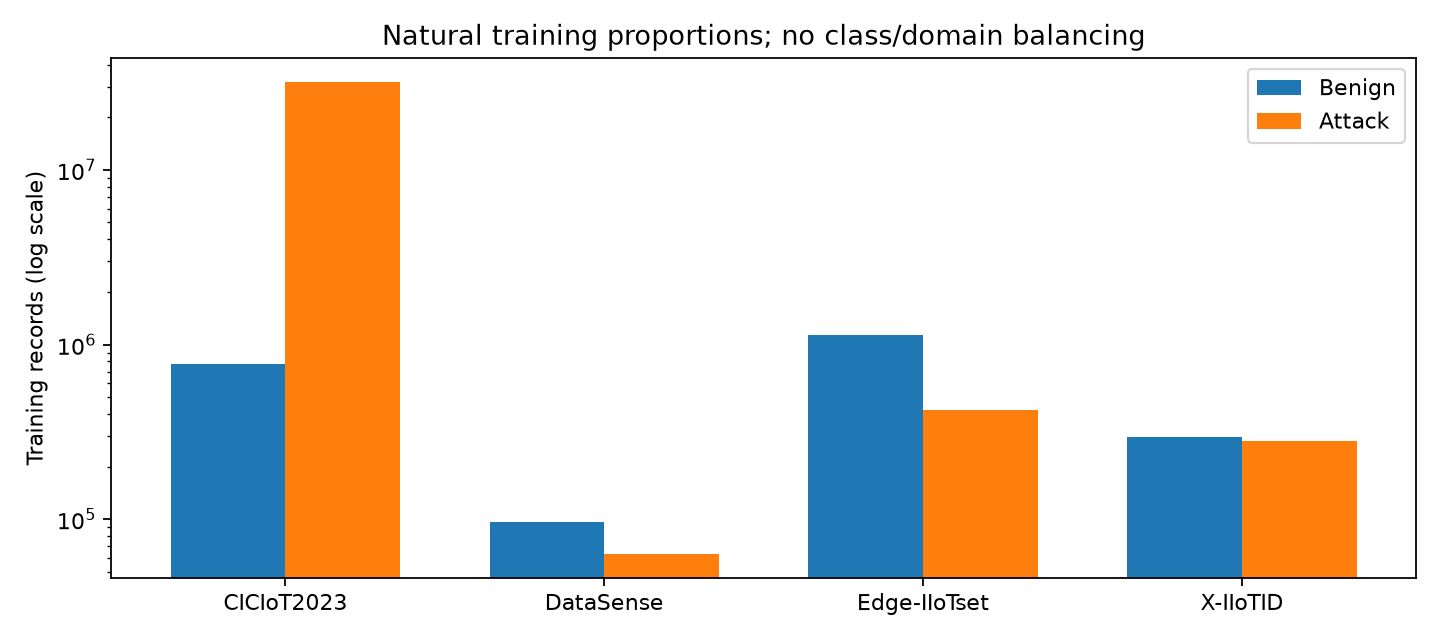

In [2]:
display(Image(filename=str(artifacts / 'report' / 'training_composition.png')))


In [3]:
files = sorted((artifacts / 'adapted_experiment').glob('*/history.json'))
history = [{'model': f.parent.name, **r} for f in files for r in json.loads(f.read_text())]
display(pd.DataFrame(history) if history else 'No completed training epochs yet.')


,model,epoch,train_loss,validation,mean_validation_macro_f1,mean_validation_ap,elapsed_seconds,training_rows
0,BiLSTM,1,0.075772,"{'DataSense': {'macro_f1': 0.867676475297301, ...",0.863167,0.928347,98.374530,35030746
1,BiLSTM,2,0.034925,"{'DataSense': {'macro_f1': 0.8397681970244011,...",0.890118,0.952125,98.957340,35030746
2,BiLSTM,3,0.030933,"{'DataSense': {'macro_f1': 0.8714794596034774,...",0.908458,0.960809,98.725707,35030746
3,BiLSTM,4,0.028319,"{'DataSense': {'macro_f1': 0.8701017245470453,...",0.913359,0.961388,98.728334,35030746
4,BiLSTM,5,0.026740,"{'DataSense': {'macro_f1': 0.8719803715253787,...",0.920114,0.968036,98.578227,35030746
...,...,...,...,...,...,...,...,...
69,MLP,16,0.021123,"{'DataSense': {'macro_f1': 0.8911797266486036,...",0.942366,0.975854,16.046993,35030746
70,MLP,17,0.021044,"{'DataSense': {'macro_f1': 0.8871050765244035,...",0.941930,0.975999,16.043968,35030746
71,MLP,18,0.021056,"{'DataSense': {'macro_f1': 0.8896974110700797,...",0.942692,0.975684,19.790076,35030746
72,MLP,19,0.020960,"{'DataSense': {'macro_f1': 0.8917947637288096,...",0.943363,0.976447,16.926661,35030746


BiLSTM


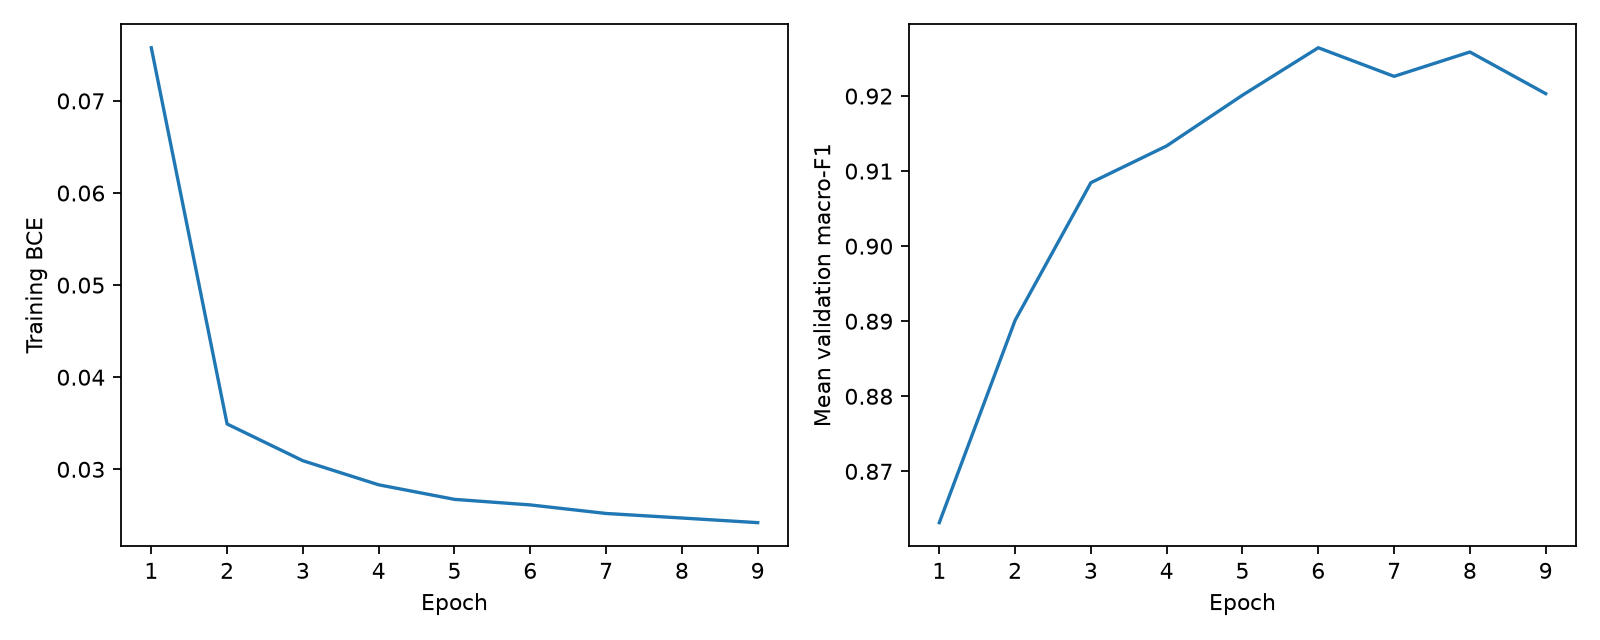

CNN1D


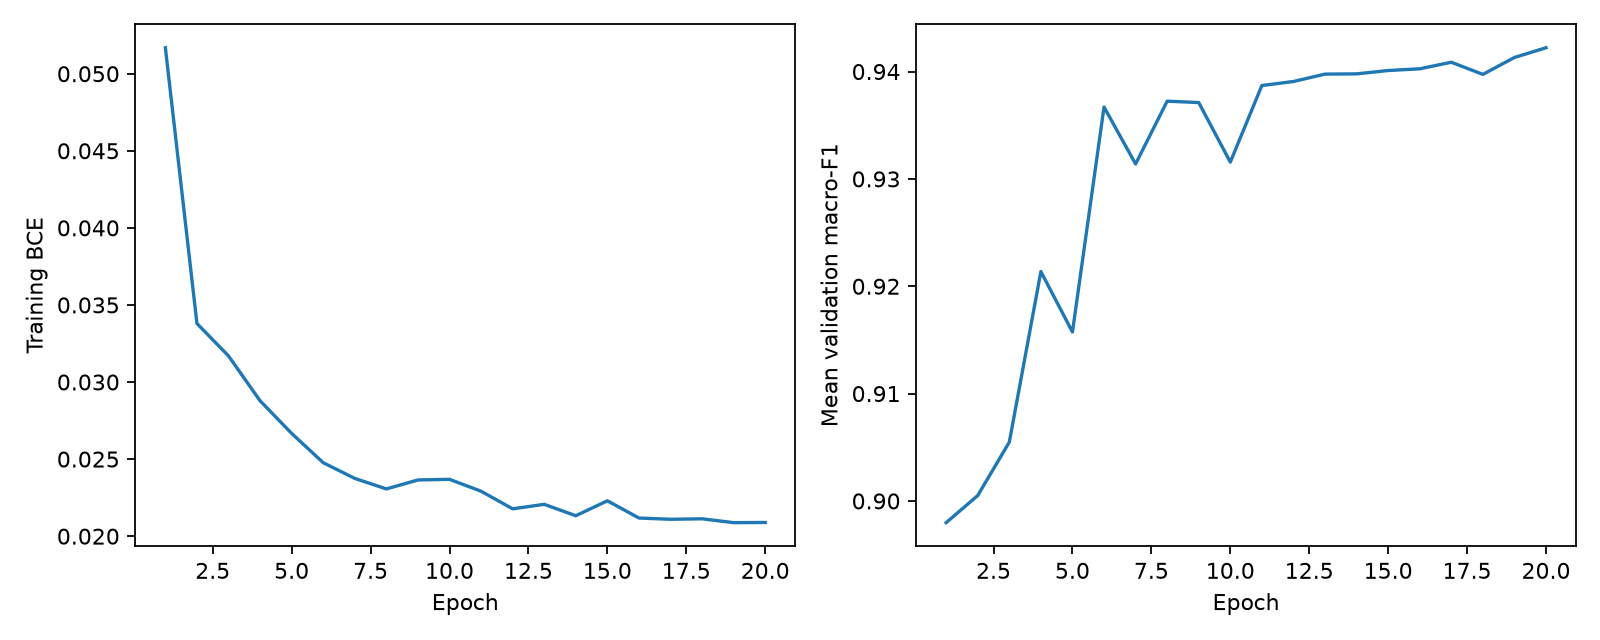

GRU


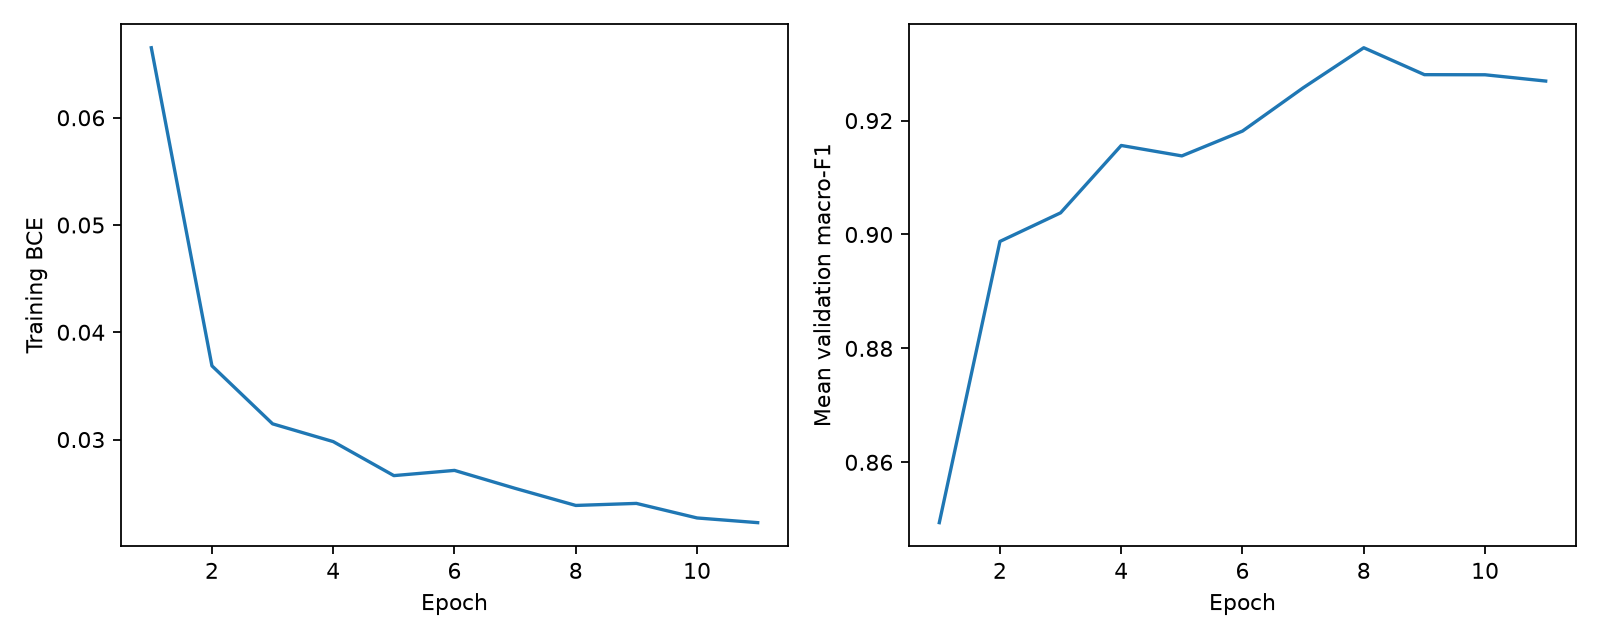

LSTM


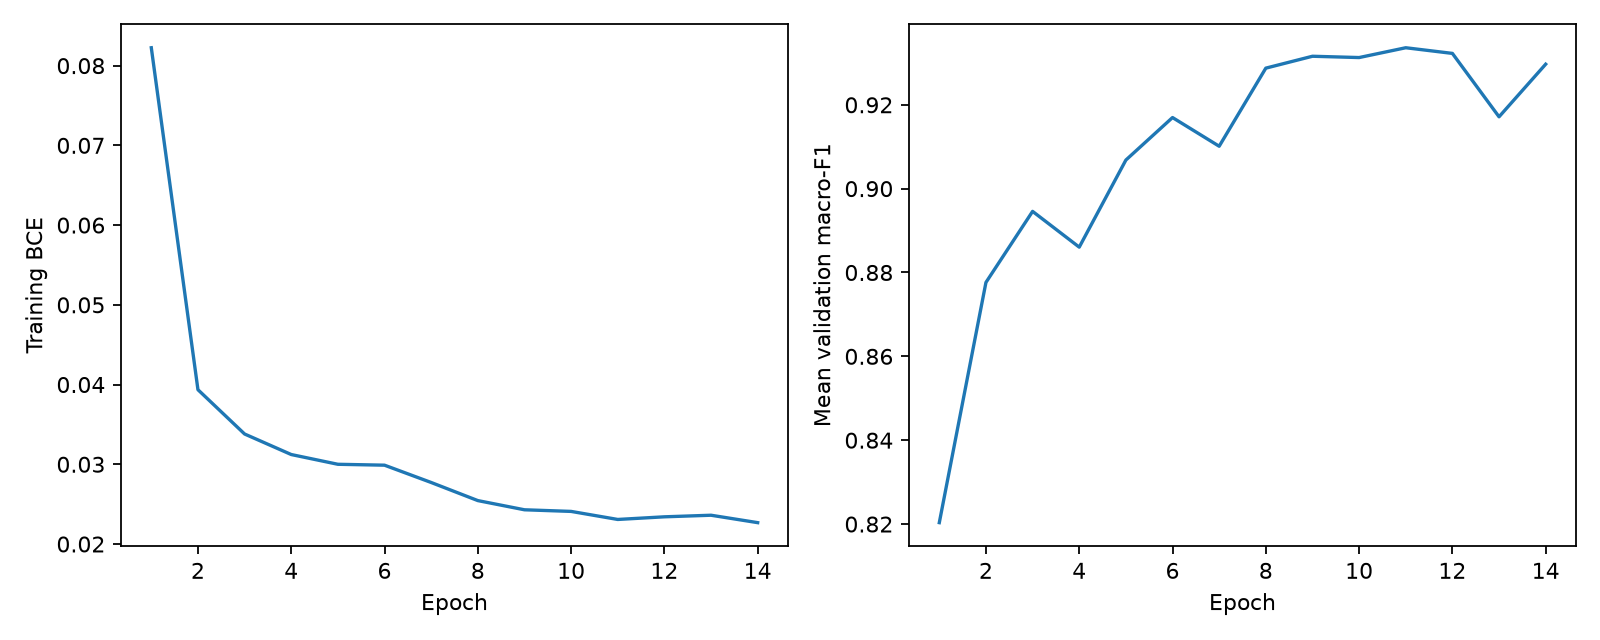

MLP


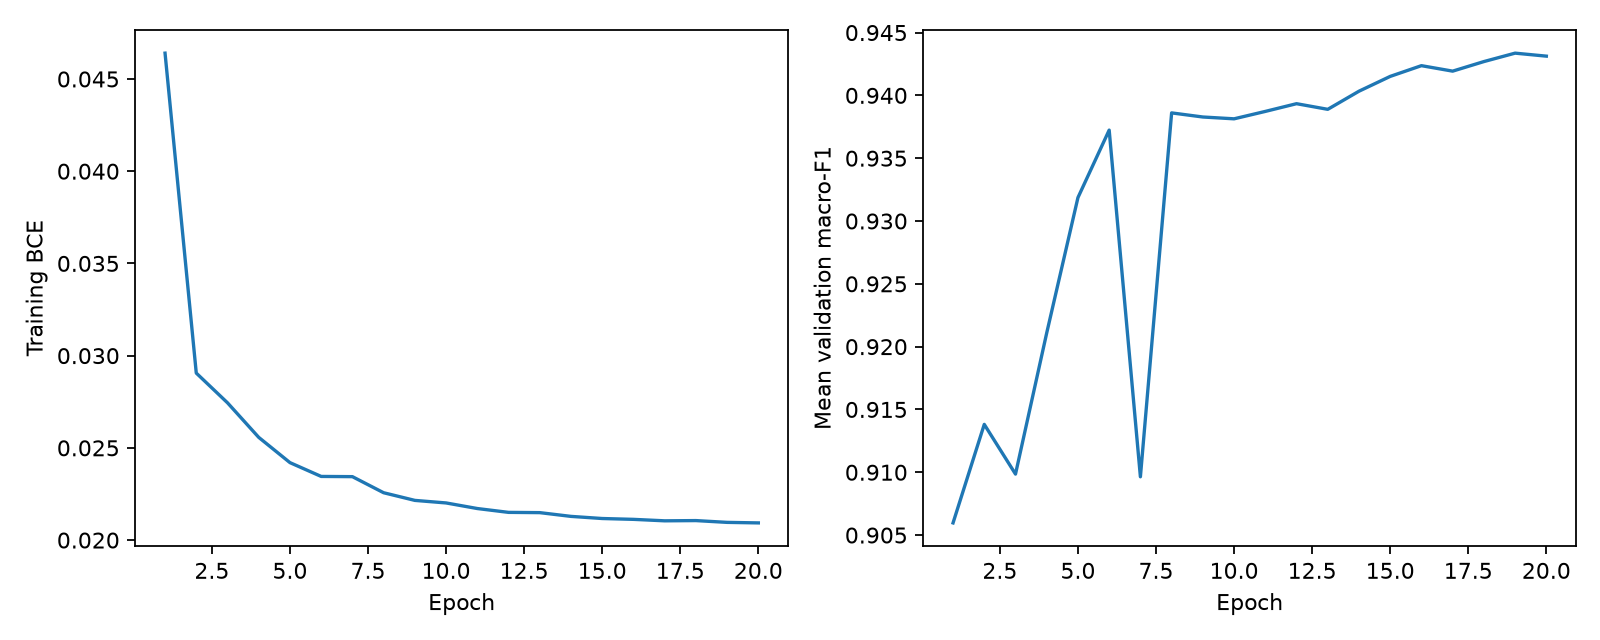

In [4]:
for plot in sorted((artifacts / 'adapted_experiment').glob('*/learning_curves.png')):
    print(plot.parent.name)
    display(Image(filename=str(plot)))


In [5]:
baseline = artifacts / 'adapted_experiment' / 'baseline.json'
display(json.loads(baseline.read_text()) if baseline.exists() else 'Baseline not selected yet.')
metrics = artifacts / 'report' / 'test_metrics.csv'
display(pd.read_csv(metrics) if metrics.exists() else 'Test evaluation not complete.')


{'selected': {'model': 'MLP',
  'validation_macro_f1': 0.9433629172857663,
  'validation_ap': 0.9764470192121453,
  'parameters': 21137,
  'epochs_run': 20},
 'candidates': [{'model': 'MLP',
   'validation_macro_f1': 0.9433629172857663,
   'validation_ap': 0.9764470192121453,
   'parameters': 21137,
   'epochs_run': 20},
  {'model': 'CNN1D',
   'validation_macro_f1': 0.9422205906432487,
   'validation_ap': 0.9757396971307769,
   'parameters': 40689,
   'epochs_run': 20},
  {'model': 'LSTM',
   'validation_macro_f1': 0.9336052038870611,
   'validation_ap': 0.9730161993329345,
   'parameters': 215569,
   'epochs_run': 14},
  {'model': 'GRU',
   'validation_macro_f1': 0.9327891947077286,
   'validation_ap': 0.9724440893989023,
   'parameters': 164881,
   'epochs_run': 11},
  {'model': 'BiLSTM',
   'validation_macro_f1': 0.9264337507457837,
   'validation_ap': 0.9697521558556347,
   'parameters': 557585,
   'epochs_run': 9}],
 'selection_uses_test': False,
 'status': 'Selected using valida

,model,dataset,n,threshold,tn,fp,fn,tp,accuracy,balanced_accuracy,...,false_negative_rate,roc_auc,average_precision,log_loss,brier_score,support_benign,support_attack,precision_benign,recall_benign,f1_benign
0,BiLSTM,CICIoT2023,7016505,0.5,141699,23030,37481,6814295,0.991376,0.927362,...,0.005470,0.997556,0.999942,0.018843,0.006059,164729,6851776,0.790819,0.860195,0.824049
1,BiLSTM,DataSense,34079,0.5,19899,621,3163,10396,0.888964,0.868230,...,0.233277,0.894885,0.901068,0.302258,0.090301,20520,13559,0.862848,0.969737,0.913175
2,BiLSTM,Edge-IIoTset,332881,0.5,241406,941,272,90262,0.996356,0.996556,...,0.003004,0.999409,0.997284,0.015259,0.003346,242347,90534,0.998875,0.996117,0.997494
3,BiLSTM,X-IIoTID,123126,0.5,57094,6119,3870,56043,0.918872,0.919303,...,0.064594,0.976754,0.978329,0.195956,0.058678,63213,59913,0.936520,0.903200,0.919558
4,CNN1D,CICIoT2023,7016505,0.5,145217,19512,37654,6814122,0.991853,0.938028,...,0.005496,0.997817,0.999948,0.017989,0.005760,164729,6851776,0.794095,0.881551,0.835541
5,CNN1D,DataSense,34079,0.5,20335,185,3385,10174,0.895243,0.870667,...,0.249650,0.906761,0.906736,0.283419,0.084853,20520,13559,0.857293,0.990984,0.919304
6,CNN1D,Edge-IIoTset,332881,0.5,241456,891,435,90099,0.996017,0.995759,...,0.004805,0.999571,0.997786,0.013348,0.003306,242347,90534,0.998202,0.996323,0.997262
7,CNN1D,X-IIoTID,123126,0.5,61973,1240,2014,57899,0.973572,0.973384,...,0.033615,0.996576,0.996588,0.076040,0.021638,63213,59913,0.968525,0.980384,0.974418
8,GRU,CICIoT2023,7016505,0.5,142273,22456,36457,6815319,0.991604,0.929179,...,0.005321,0.997661,0.999944,0.018370,0.005906,164729,6851776,0.796022,0.863679,0.828472
9,GRU,DataSense,34079,0.5,20398,122,3641,9918,0.889580,0.862762,...,0.268530,0.898815,0.899957,0.302094,0.090570,20520,13559,0.848538,0.994055,0.915550


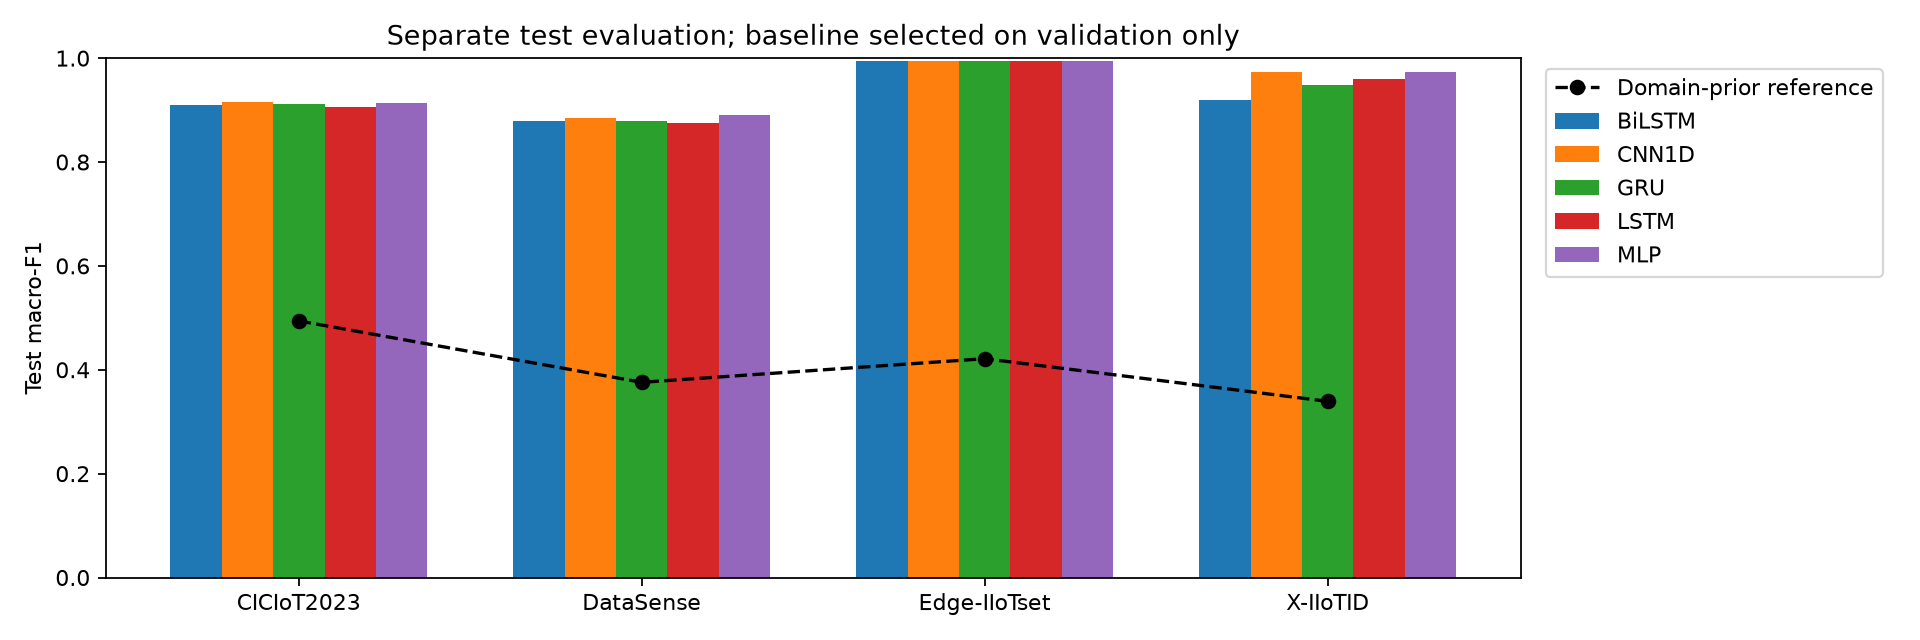

In [6]:
comparison = artifacts / 'report' / 'test_comparison.png'
if comparison.exists():
    display(Image(filename=str(comparison)))


In [7]:
latency = artifacts / 'report' / 'inference_latency.csv'
if latency.exists():
    display(pd.read_csv(latency))
    print('Warm workstation inference only; extraction, scaling, transfer, queueing and window delay excluded.')


,model,dataset,device,batch_size,repetitions,median_ms,p95_ms,observations_per_second
0,MLP,DataSense,cpu,1,20,0.12700,0.146770,7.874017e+03
1,MLP,DataSense,cpu,512,20,0.50190,0.564720,1.020124e+06
2,MLP,Edge-IIoTset,cpu,1,20,0.08500,0.090155,1.176470e+04
3,MLP,Edge-IIoTset,cpu,512,20,0.40600,0.464750,1.261084e+06
4,MLP,CICIoT2023,cpu,1,20,0.08195,0.090595,1.220256e+04
...,...,...,...,...,...,...,...,...
75,BiLSTM,Edge-IIoTset,cuda,512,20,1.38350,1.406465,3.700759e+05
76,BiLSTM,CICIoT2023,cuda,1,20,1.21200,1.285565,8.250825e+02
77,BiLSTM,CICIoT2023,cuda,512,20,1.38505,1.407865,3.696617e+05
78,BiLSTM,X-IIoTID,cuda,1,20,1.21025,1.263990,8.262756e+02


Warm workstation inference only; extraction, scaling, transfer, queueing and window delay excluded.


MLP CICIoT2023


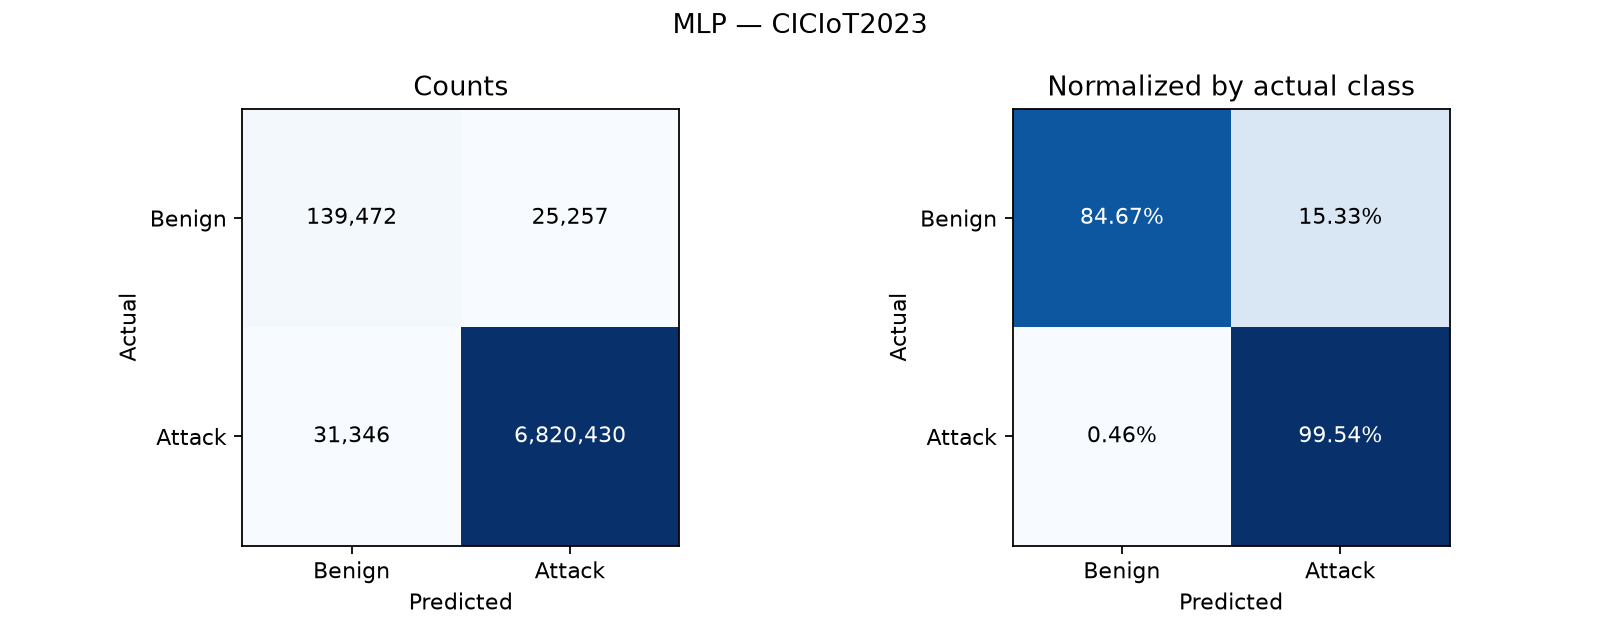

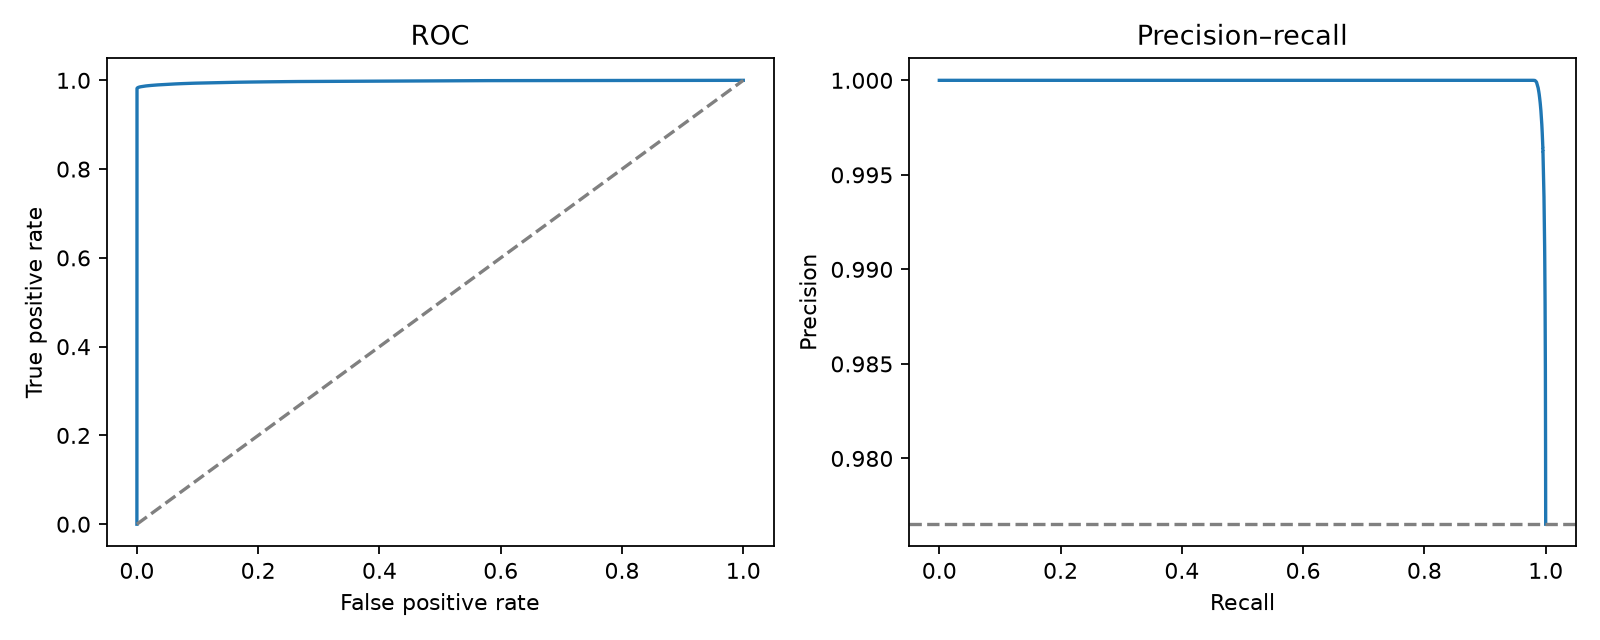

MLP DataSense


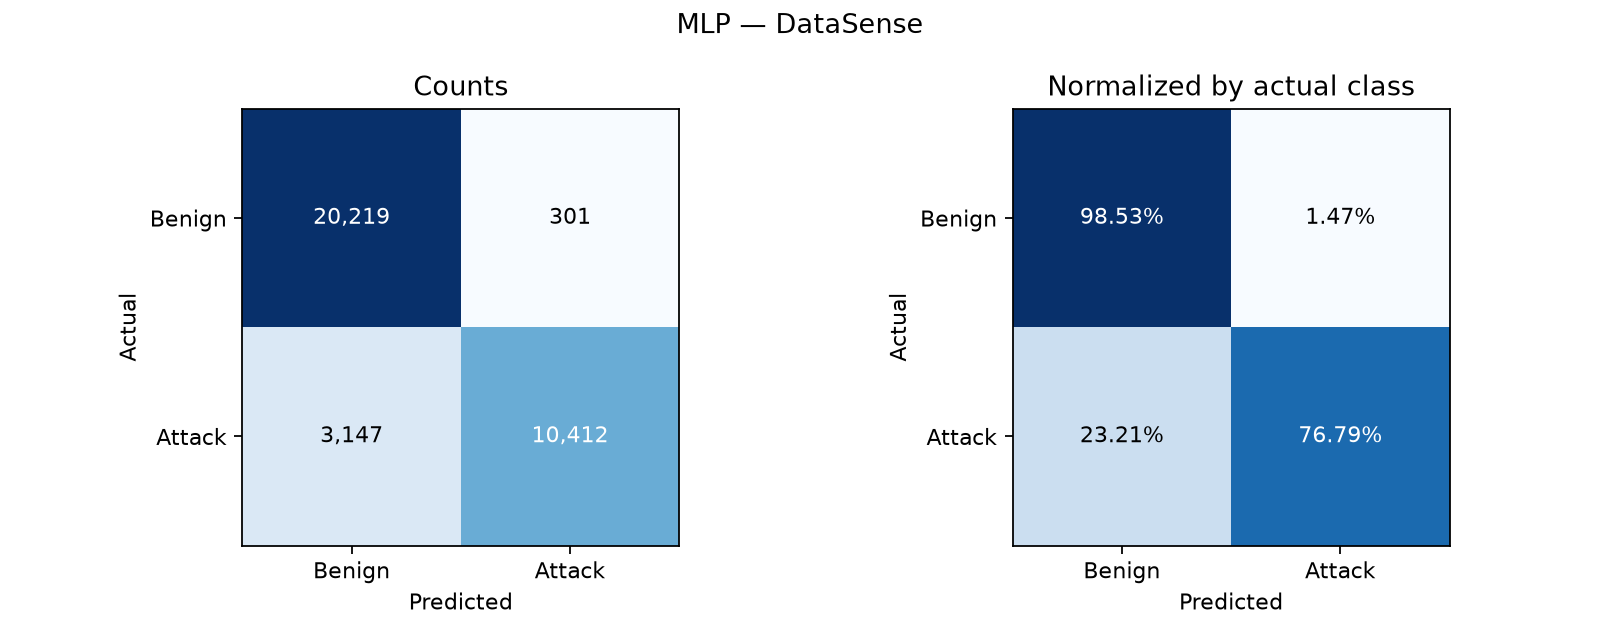

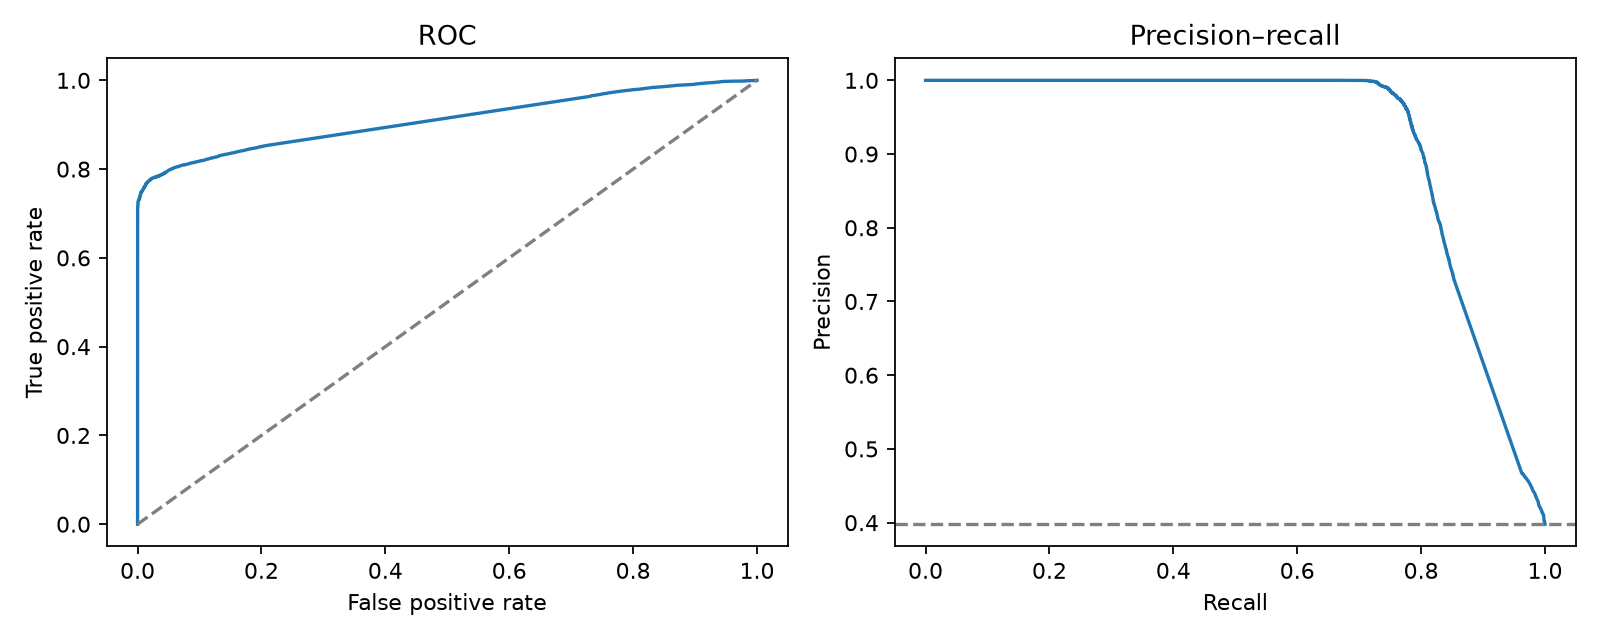

MLP Edge-IIoTset


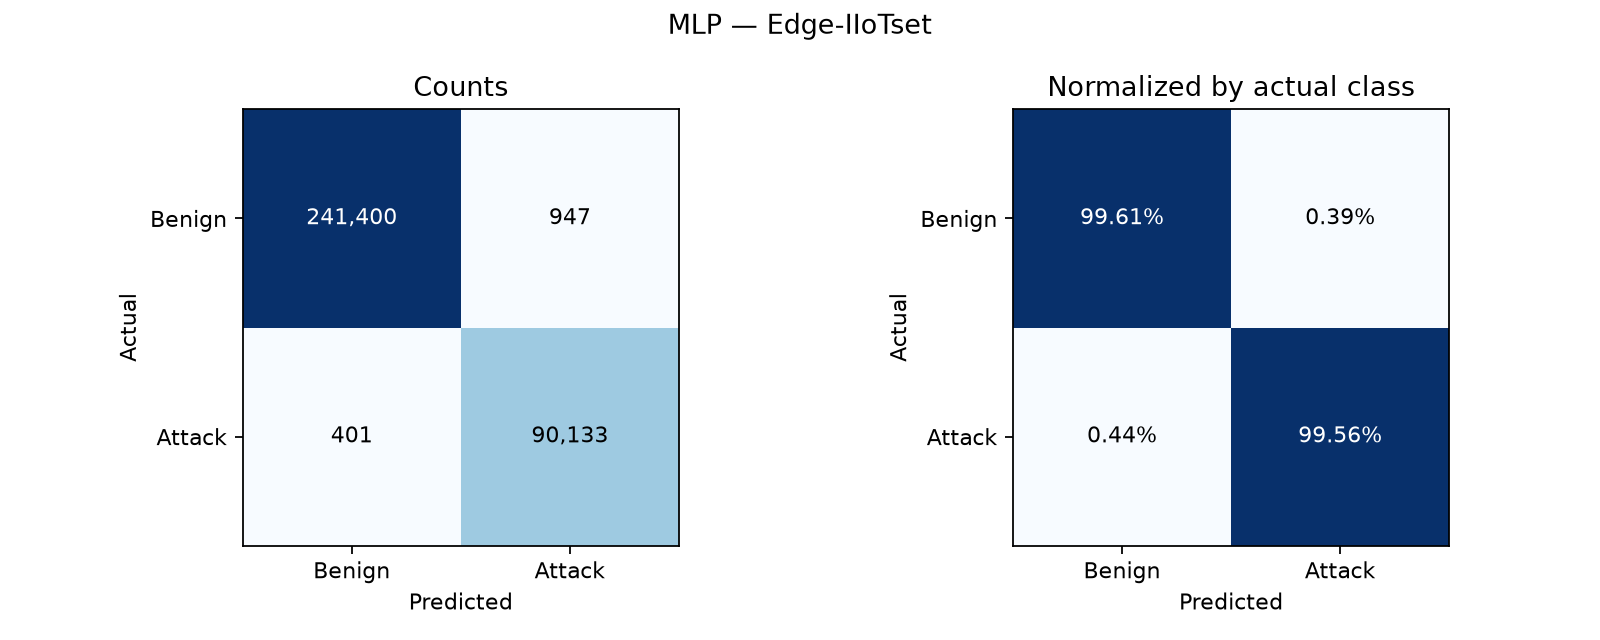

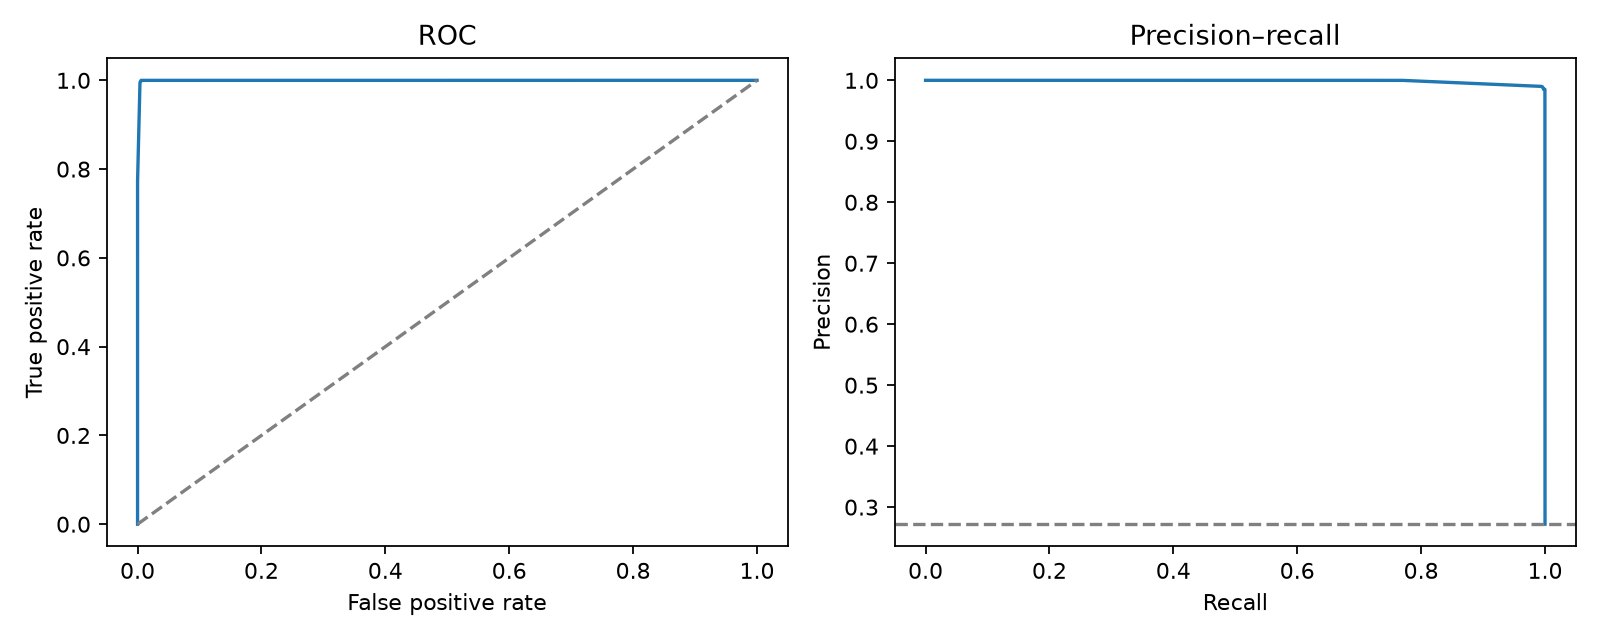

MLP X-IIoTID


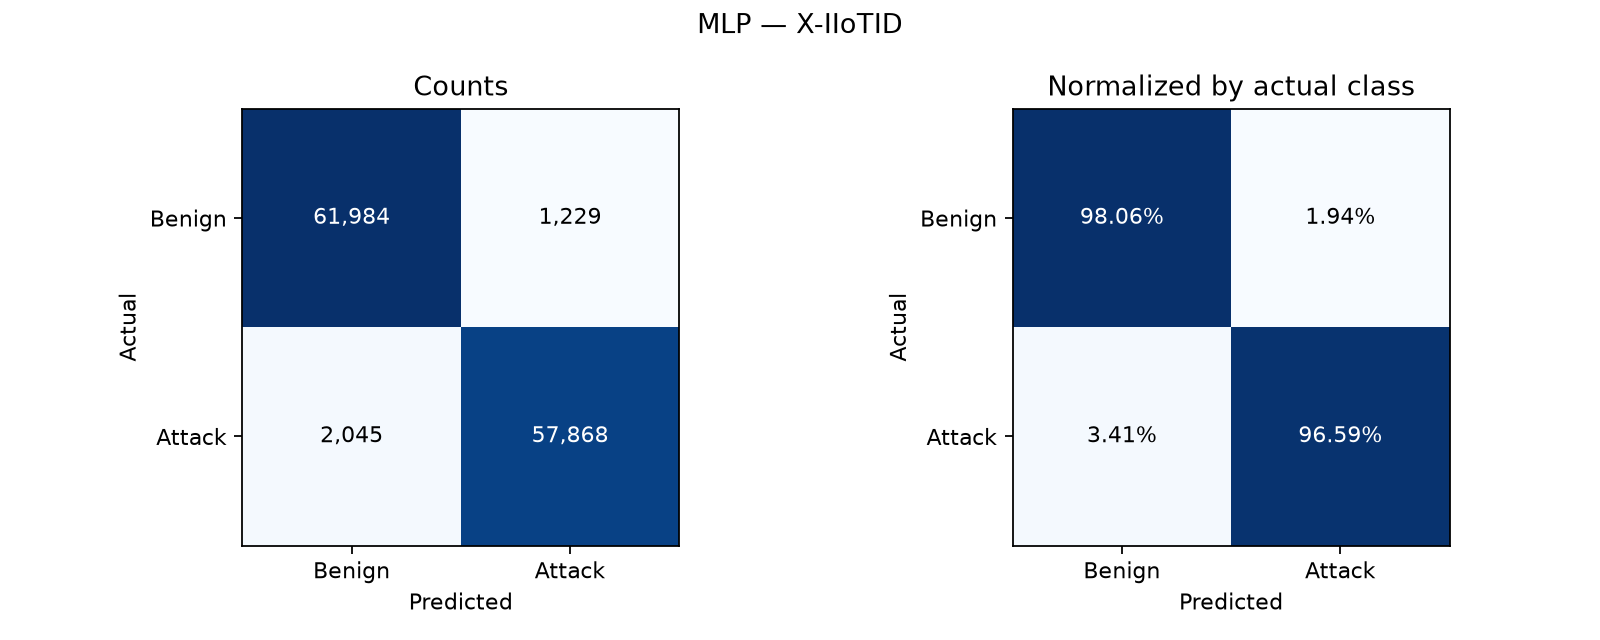

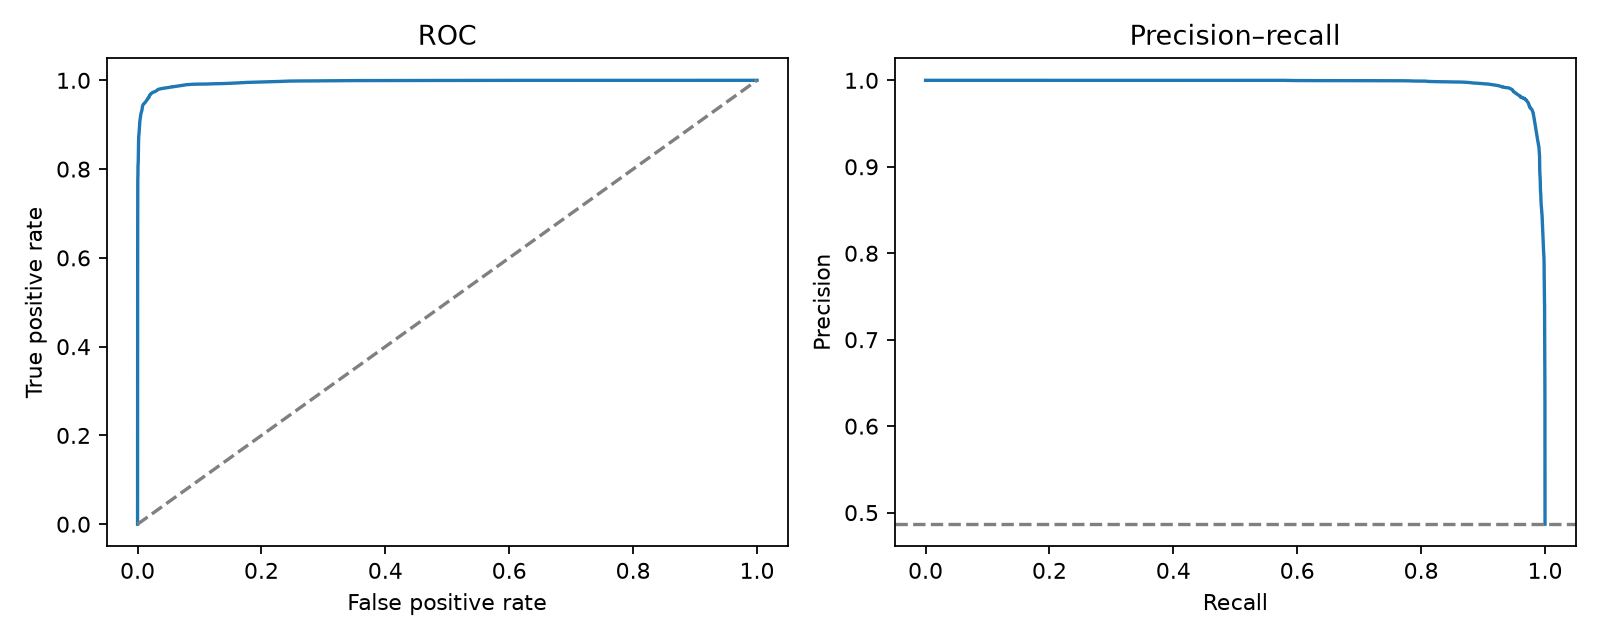

In [8]:
if baseline.exists():
    selected = json.loads(baseline.read_text())['selected']['model']
    for folder in sorted((artifacts / 'adapted_experiment' / selected / 'test').glob('*')):
        print(selected, folder.name)
        for name in ['confusion_matrix.png', 'roc_pr.png']:
            if (folder / name).exists():
                display(Image(filename=str(folder / name)))
else:
    print('Baseline plots pending; all model plots will be saved in artifacts.')


# Expanded comparison and overall baseline

Eleven new candidates are compared with the previous MLP using validation scores only. Native observation units differ; these are authorized dataset-specific pipelines, not harmonized flows. See [Expanded methods](EXTENDED_EXPERIMENT_METHOD.md) and [Full results](EXTENDED_EXPERIMENT_REPORT.md).

In [9]:
extended = artifacts / 'extended_report'
status = json.loads((extended / 'selection_status.json').read_text())
display({'status': status['status'], 'pending': status.get('pending', []), 'selection_uses_test': status.get('selection_uses_test', False)})
for progress_path in [extended / 'remaining_progress.json', artifacts / 'expanded_classical' / 'cpu_progress.json', artifacts / 'expanded_classical' / 'gb_progress.json']:
    if progress_path.exists(): display(json.loads(progress_path.read_text()))
display(pd.read_csv(extended / 'validation_comparison.csv'))
overall_path = artifacts / 'overall_baseline.json'
if overall_path.exists():
    overall = json.loads(overall_path.read_text())
    display({k: overall[k] for k in ['status', 'rule', 'scope']})
    display(pd.DataFrame([{k: c.get(k) for k in ['model', 'validation_macro_f1', 'validation_ap', 'artifact_bytes']} for c in [overall['best_new'], overall['previous_MLP']]]))

{'status': 'verified_complete', 'pending': [], 'selection_uses_test': False}

{'stage': 'complete', 'status': 'complete'}

{'stage': 'complete',
 'models': ['NB', 'DT', 'RF', 'KNN'],
 'test_evaluations': 16}

{'stage': 'complete', 'model': 'GB', 'test_evaluations': 4}

,model,family,validation_macro_f1,validation_ap,artifact_bytes,parameters,epochs_run,fit_seconds
0,GB,expanded_classical,0.962042,0.985641,2168929,NaN,NaN,NaN
1,KNN,expanded_classical,0.950304,0.974192,10736476216,NaN,NaN,157.873237
2,RF,expanded_classical,0.946305,0.979078,5280633,NaN,NaN,1641.833265
3,MLP,adapted_experiment,0.943363,0.976447,95769,21137.0,20.0,NaN
4,Transformer,expanded_neural,0.934062,0.972859,312079,72593.0,20.0,NaN
5,Autoencoder,expanded_neural,0.929756,0.972271,99385,19930.0,12.0,NaN
6,GNN,expanded_neural,0.928887,0.969497,83497,16481.0,9.0,NaN
7,SVM,expanded_classical,0.914836,0.948192,104735,3669.0,20.0,NaN
8,GAN,expanded_neural,0.913244,0.966660,346197,81196.0,14.0,NaN
9,DT,expanded_classical,0.907797,0.958132,336873,NaN,NaN,165.850605


{'status': 'verified_complete',
 'rule': 'Highest mean validation macro-F1, then mean AP; smaller saved artifact breaks new-candidate ties; retain incumbent MLP on exact validation pair tie',
 'scope': 'Known-domain native-schema adapted pipelines; reused historical test sets, not unseen-domain transfer'}

,model,validation_macro_f1,validation_ap,artifact_bytes
0,GB,0.962042,0.985641,2168929
1,MLP,0.943363,0.976447,95769


,model,dataset,n,threshold,tn,fp,fn,tp,support_benign,support_attack,...,mcc,specificity,false_positive_rate,false_negative_rate,roc_auc,average_precision,log_loss,brier_score,ranking_score,probability_note
0,GB,DataSense,34079,0.5,20501,19,1903,11656,20520,13559,...,0.885656,0.999074,0.000926,0.140350,0.958807,0.942822,0.170704,0.048853,"raw decision score, avoiding sigmoid saturatio...",Sigmoid of binary-logistic boosted-tree margin
1,GB,Edge-IIoTset,332881,0.5,241408,939,229,90305,242347,90534,...,0.991176,0.996125,0.003875,0.002529,0.999579,0.997813,0.012749,0.003109,"raw decision score, avoiding sigmoid saturatio...",Sigmoid of binary-logistic boosted-tree margin
2,GB,CICIoT2023,7016505,0.5,141745,22984,28401,6823375,164729,6851776,...,0.842920,0.860474,0.139526,0.004145,0.998136,0.999955,0.016394,0.005193,"raw decision score, avoiding sigmoid saturatio...",Sigmoid of binary-logistic boosted-tree margin
3,GB,X-IIoTID,123126,0.5,62502,711,497,59416,63213,59913,...,0.980371,0.988752,0.011248,0.008295,0.999487,0.999474,0.030030,0.007883,"raw decision score, avoiding sigmoid saturatio...",Sigmoid of binary-logistic boosted-tree margin
4,KNN,DataSense,34079,0.5,20238,282,2474,11085,20520,13559,...,0.834444,0.986257,0.013743,0.182462,0.930680,0.912358,0.609090,0.070416,NaN,NaN
5,KNN,Edge-IIoTset,332881,0.5,241061,1286,172,90362,242347,90534,...,0.989017,0.994694,0.005306,0.001900,0.998155,0.990248,0.098261,0.003543,NaN,NaN
6,KNN,CICIoT2023,7016505,0.5,138987,25742,36731,6815045,164729,6851776,...,0.812384,0.843731,0.156269,0.005361,0.984159,0.999276,0.080861,0.006544,NaN,NaN
7,KNN,X-IIoTID,123126,0.5,62383,830,778,59135,63213,59913,...,0.973863,0.986870,0.013130,0.012985,0.995673,0.993485,0.160517,0.010452,NaN,NaN
8,RF,DataSense,34079,0.5,20457,63,2324,11235,20520,13559,...,0.858319,0.996930,0.003070,0.171399,0.935719,0.933657,0.260565,0.068234,NaN,NaN
9,RF,Edge-IIoTset,332881,0.5,241403,944,2734,87800,242347,90534,...,0.972016,0.996105,0.003895,0.030199,0.997443,0.987063,0.093360,0.016239,NaN,NaN


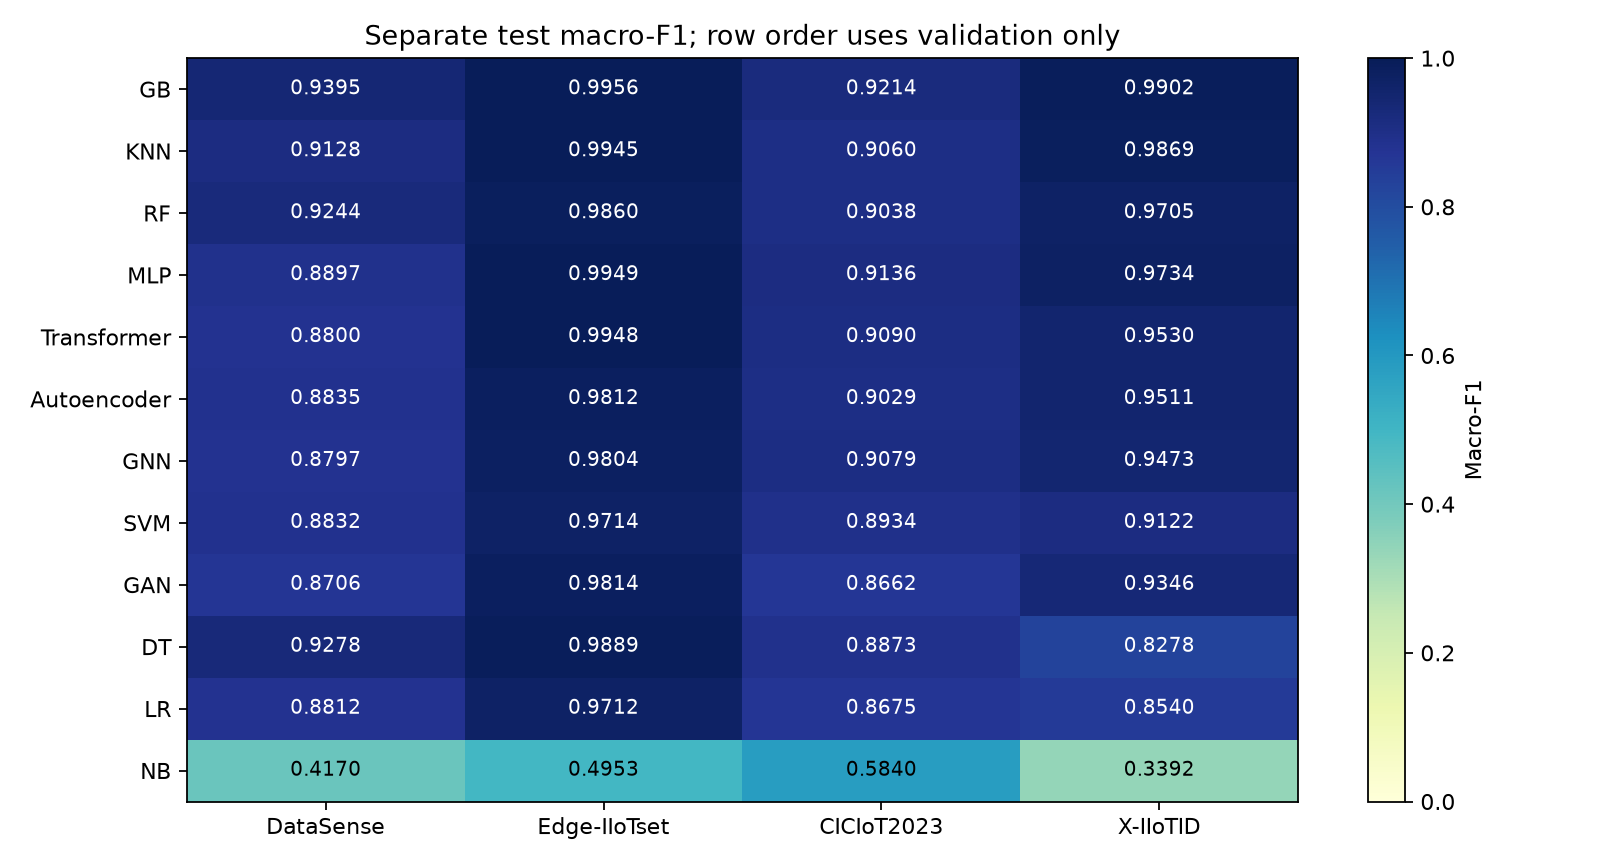

In [10]:
display(pd.read_csv(extended / 'all_test_metrics.csv'))
display(Image(filename=str(extended / 'test_macro_f1.png')))

Overall baseline: GB
DataSense


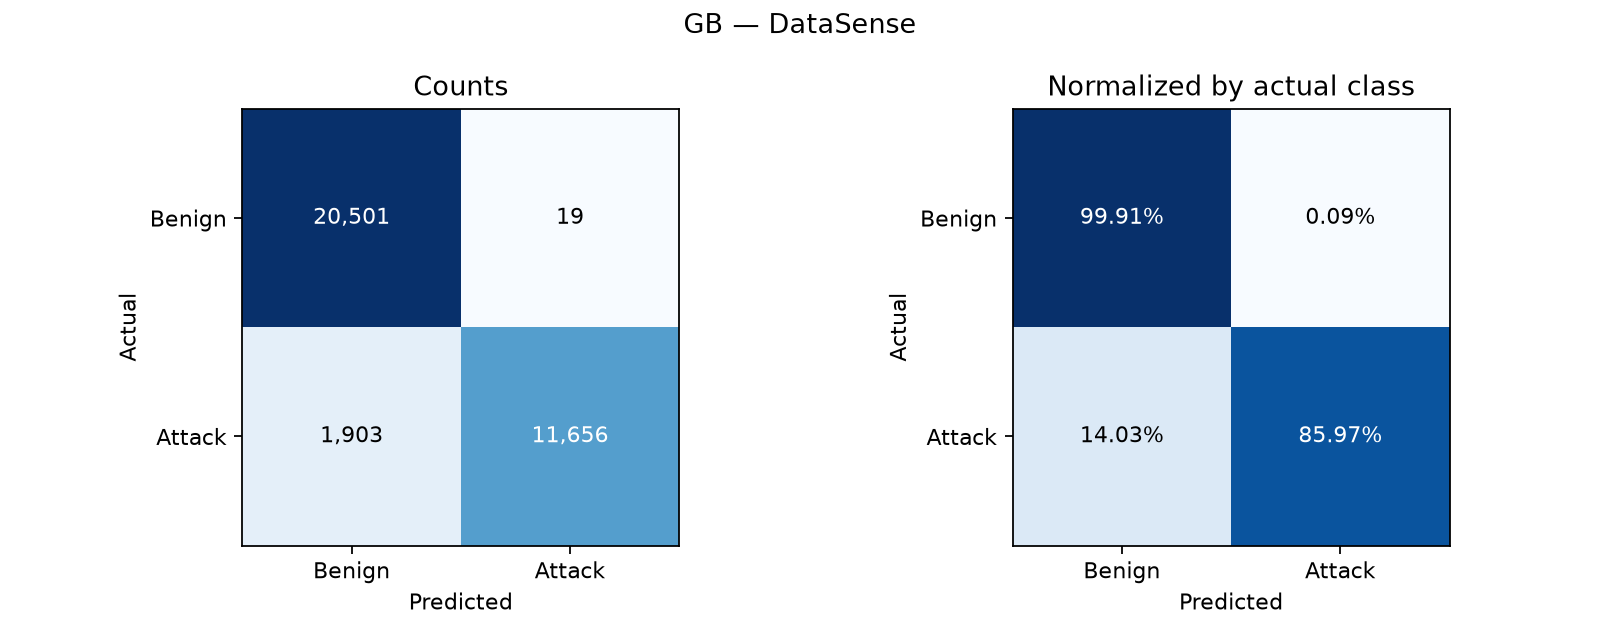

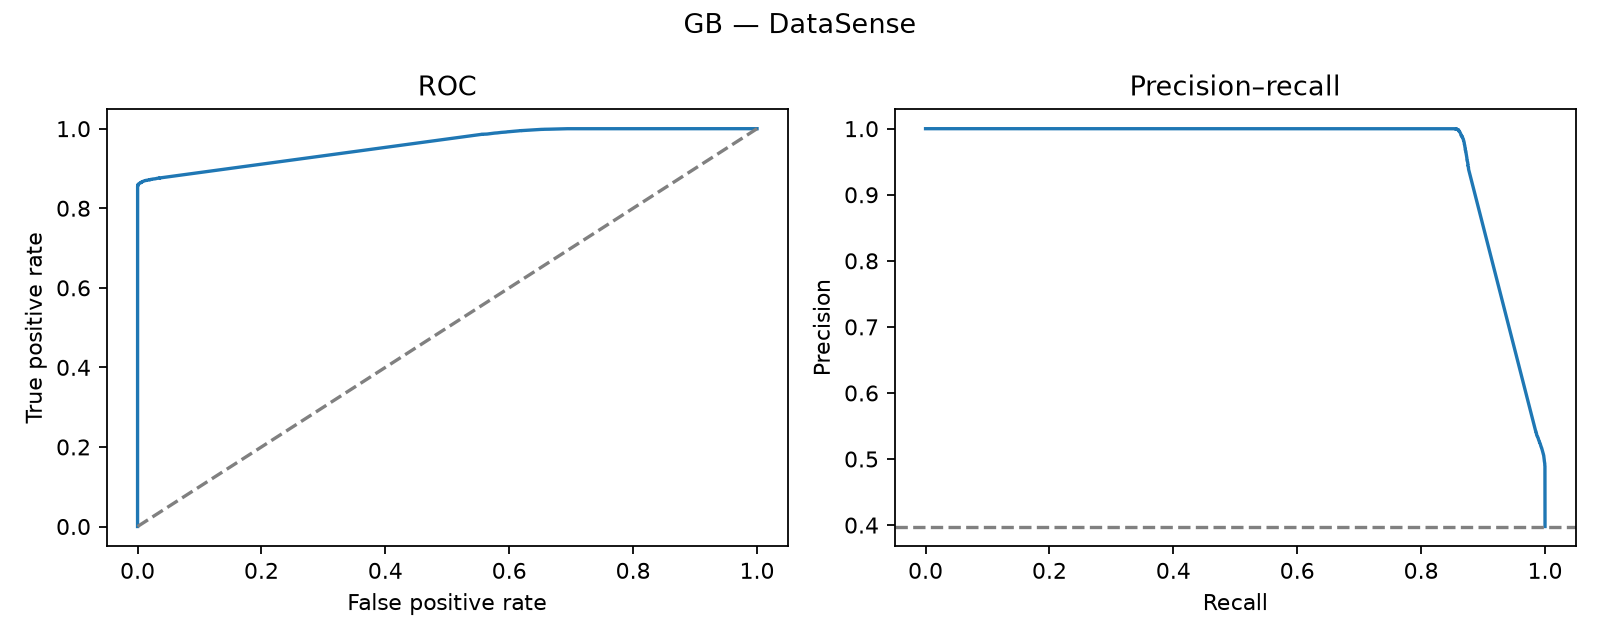

Edge-IIoTset


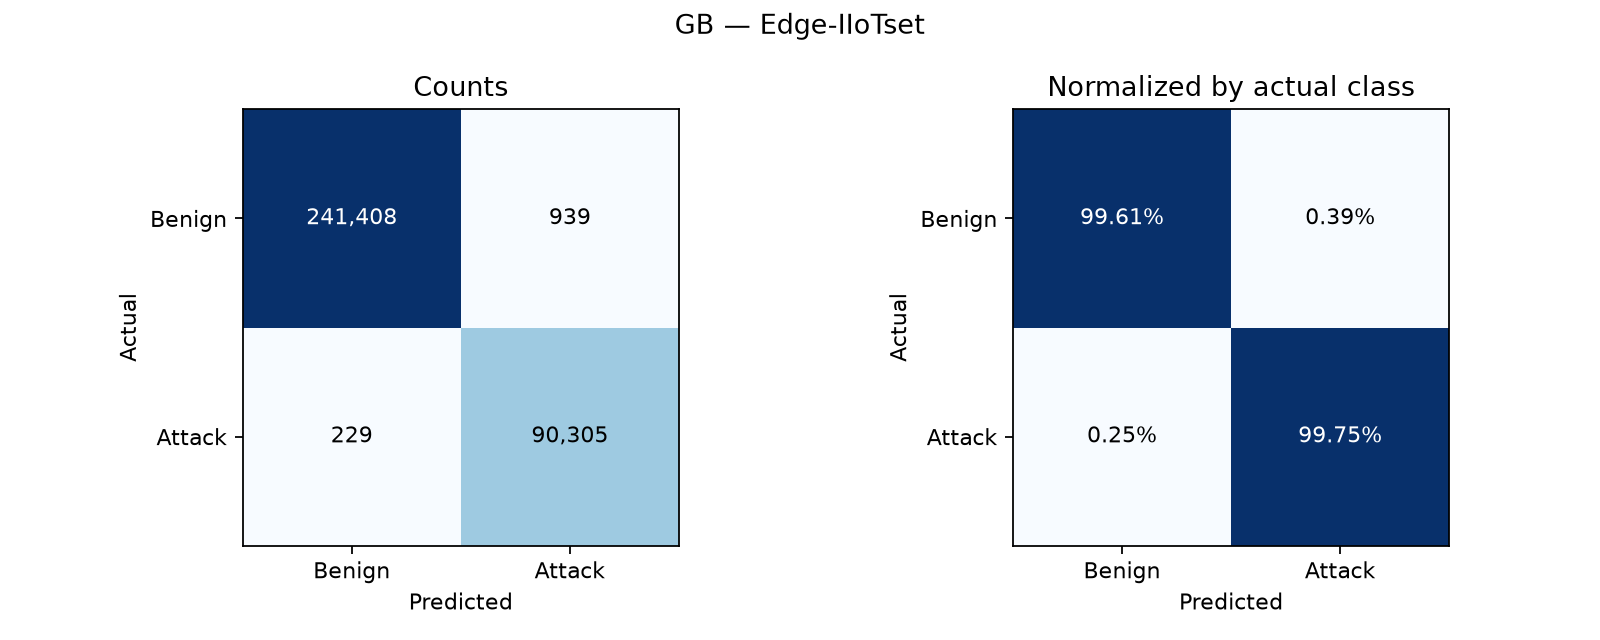

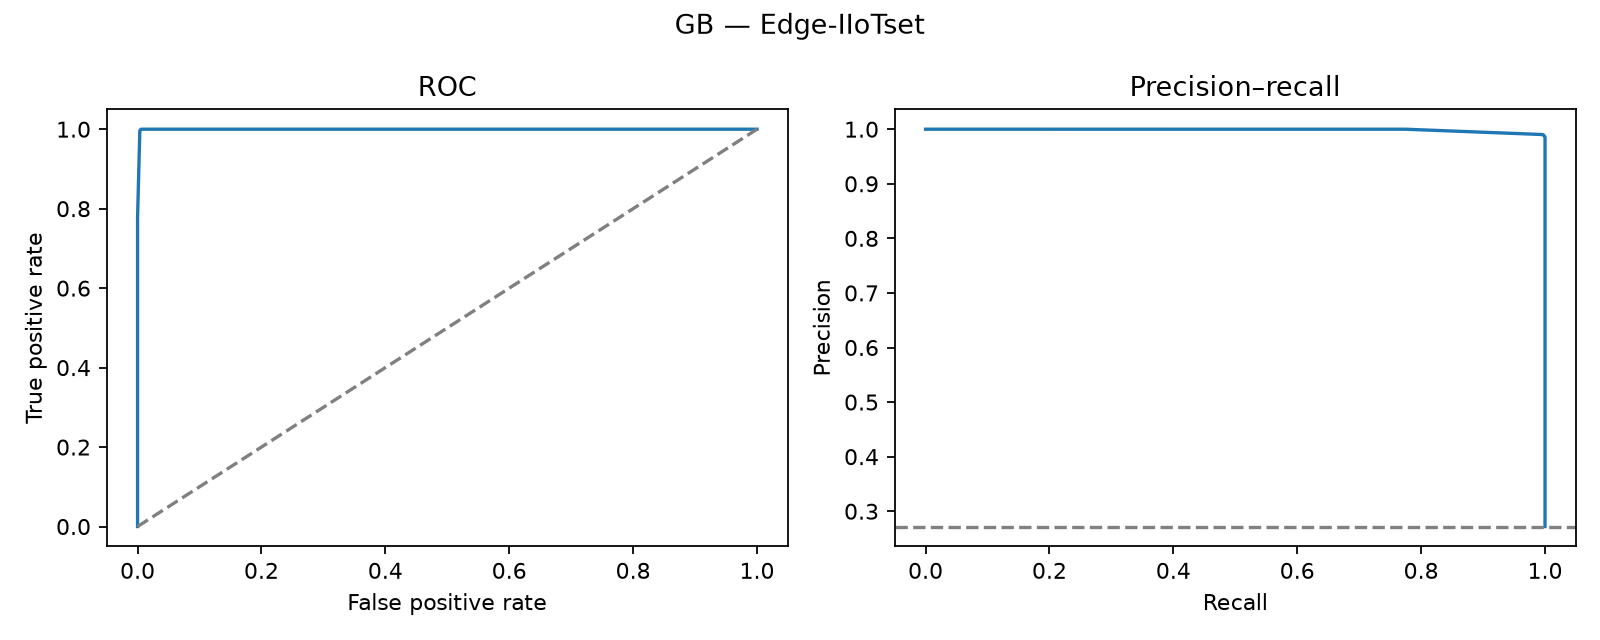

CICIoT2023


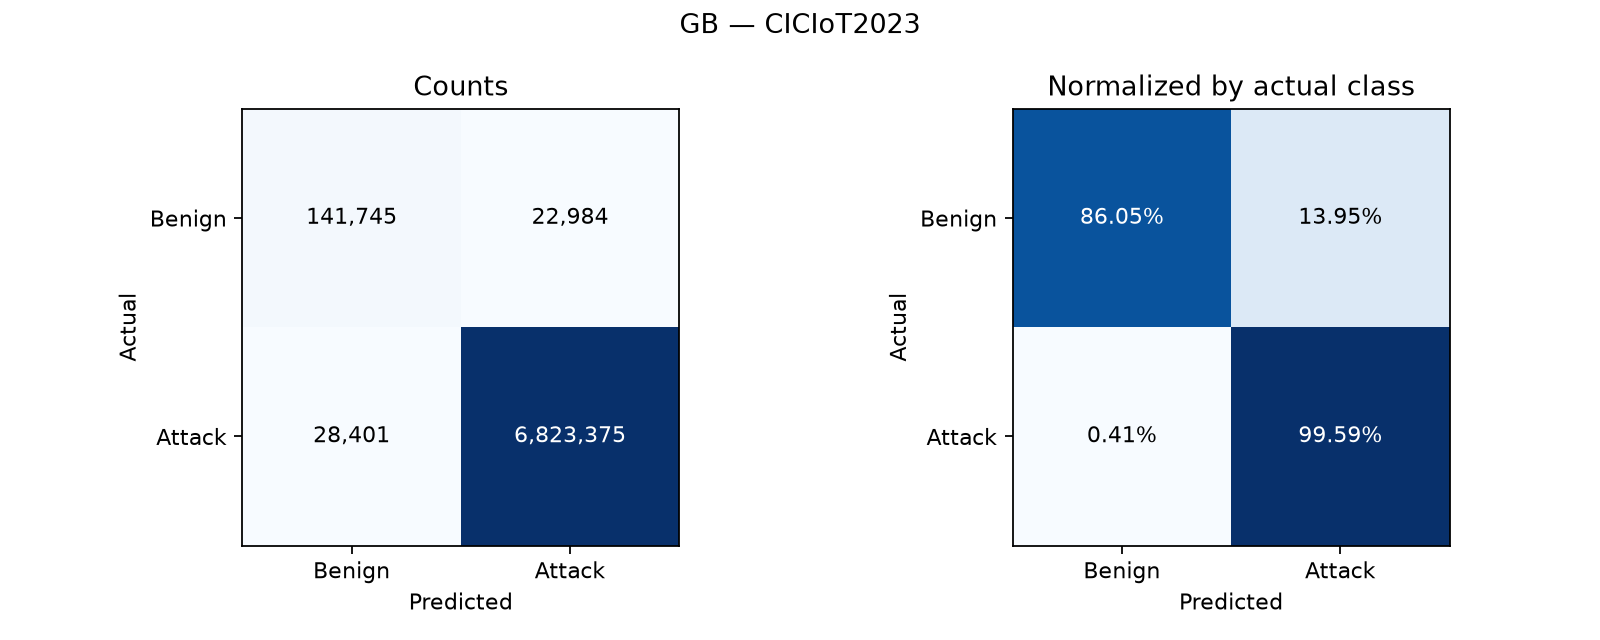

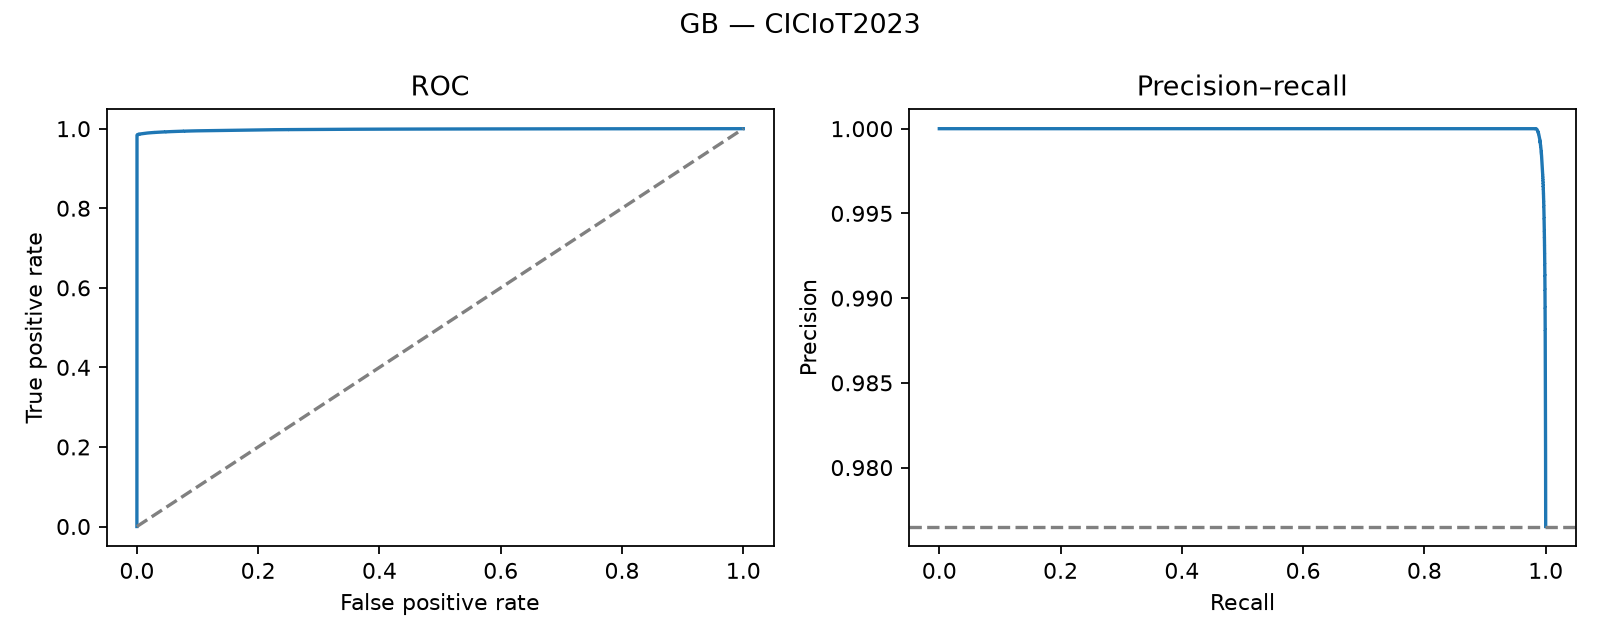

X-IIoTID


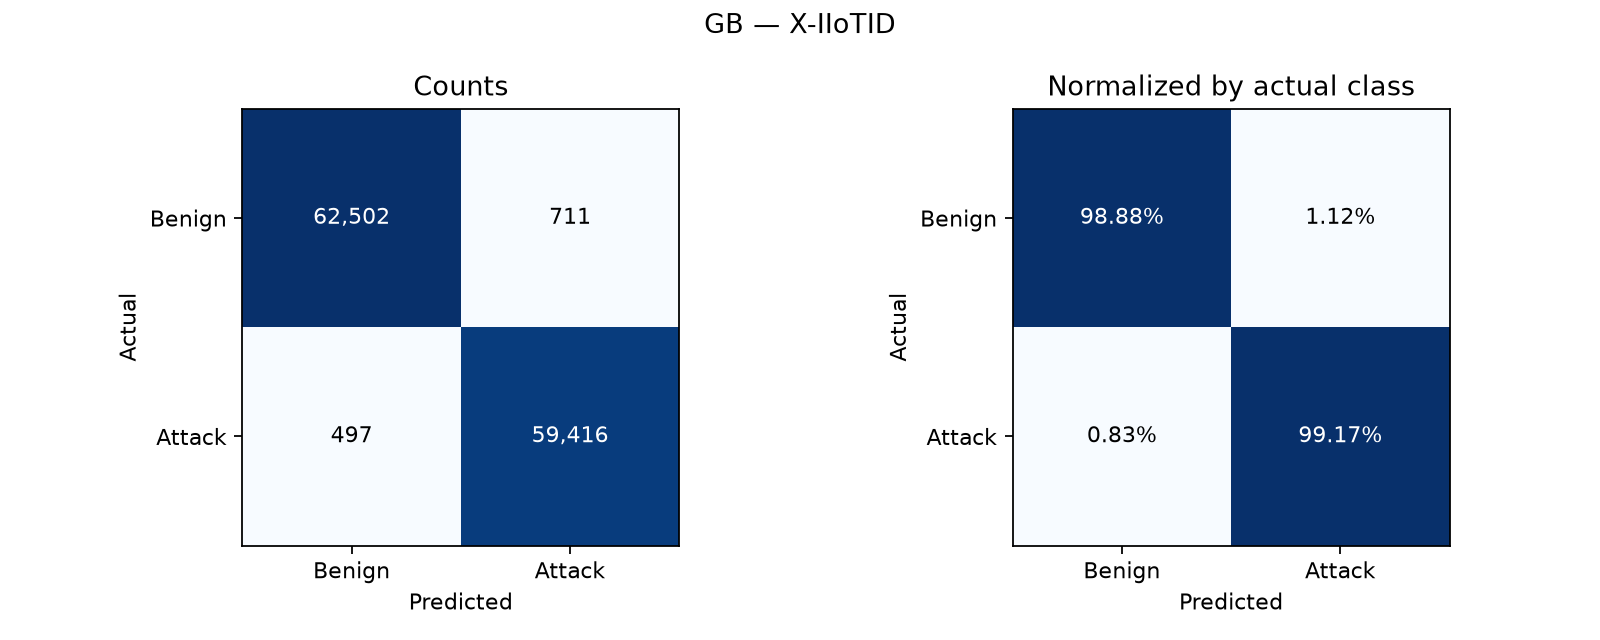

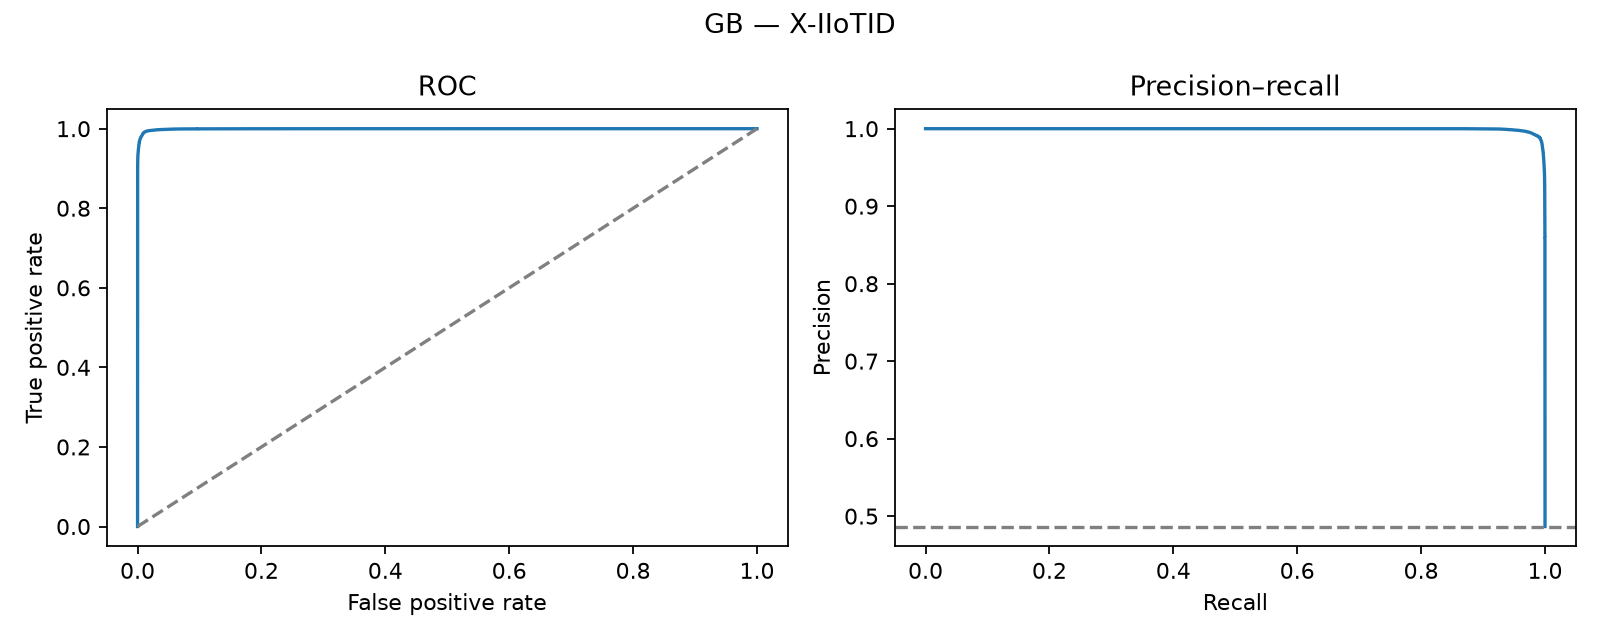

{'status': 'passed',
 'new_models': 11,
 'new_model_test_evaluations': 44,
 'evaluations': [{'model': 'Autoencoder',
   'dataset': 'DataSense',
   'rows': 34079,
   'status': 'passed'},
  {'model': 'Autoencoder',
   'dataset': 'Edge-IIoTset',
   'rows': 332881,
   'status': 'passed'},
  {'model': 'Autoencoder',
   'dataset': 'CICIoT2023',
   'rows': 7016505,
   'status': 'passed'},
  {'model': 'Autoencoder',
   'dataset': 'X-IIoTID',
   'rows': 123126,
   'status': 'passed'},
  {'model': 'GNN', 'dataset': 'DataSense', 'rows': 34079, 'status': 'passed'},
  {'model': 'GNN',
   'dataset': 'Edge-IIoTset',
   'rows': 332881,
   'status': 'passed'},
  {'model': 'GNN',
   'dataset': 'CICIoT2023',
   'rows': 7016505,
   'status': 'passed'},
  {'model': 'GNN', 'dataset': 'X-IIoTID', 'rows': 123126, 'status': 'passed'},
  {'model': 'Transformer',
   'dataset': 'DataSense',
   'rows': 34079,
   'status': 'passed'},
  {'model': 'Transformer',
   'dataset': 'Edge-IIoTset',
   'rows': 332881,
   'st

{'status': 'passed',
 'model': 'GB',
 'load_seconds': 0.141656200052239,
 'domains': [{'dataset': 'DataSense',
   'sample_rows': [8,
    21,
    26,
    57,
    61,
    64,
    65,
    80,
    81,
    82,
    84,
    86,
    97,
    98,
    102,
    115,
    19334,
    20045,
    21376,
    29023,
    41476,
    46053,
    51894,
    84331,
    91542,
    98238,
    99608,
    100624,
    102208,
    102253,
    113424,
    116245,
    119222,
    124082,
    147312,
    149508,
    159210,
    163722,
    167618,
    173682,
    176266,
    177952,
    178900,
    187166,
    190920,
    195212,
    210441,
    221347],
   'rows': 48,
   'maximum_probability_difference': 1.5539702800937416e-07,
   'absolute_tolerance': 1e-05,
   'prediction_seconds': 0.006061999942176044,
   'status': 'passed'},
  {'dataset': 'Edge-IIoTset',
   'sample_rows': [8,
    16,
    28,
    37,
    41,
    45,
    46,
    48,
    49,
    56,
    64,
    70,
    77,
    89,
    91,
    101,
    169063,
    215

In [11]:
if overall_path.exists():
    selected = json.loads(overall_path.read_text())['selected']
    print('Overall baseline:', selected['model'])
    for domain in ['DataSense', 'Edge-IIoTset', 'CICIoT2023', 'X-IIoTID']:
        print(domain)
        for figure in ['confusion_matrix.png', 'roc_pr.png']:
            display(Image(filename=str(project / selected['test_directory'] / domain / figure)))
for verification in ['verification.json', 'loader_verification.json']:
    check = extended / verification
    if check.exists(): display(json.loads(check.read_text()))

The test sets were inspected in the initial stage and are reused here. Random record splits do not isolate captures/devices/duplicates/time. GNN nodes represent feature groups, transformer tokens are not temporal observations, and the GAN is a classifier rather than an adversarial defense. No adversarial robustness, explanation quality or end-to-end real-time edge performance is established.